# A coated laser mirror: thin film design, polarization ray trace and vectorial focus

A 45° fold mirror sits in the beam path of almost every laser head. Its
coating is designed for high reflectance, but it also reflects s and p
polarized light with different phases (**retardance**) and slightly
different amplitudes (**diattenuation**), both depending on the angle of
incidence. This notebook follows one mirror from its layer stack to the
focal spot of an Nd:YAG laser (1064 nm):

1. mirror coatings: bare and protected silver, and a dielectric quarter
   wave stack designed for 45° (`coatings.Layer.quarter_wave(angle=...)`),
2. retardance over the angle of incidence, the Goos–Hänchen shift, and a
   **phase compensated** design with optimized top layers,
3. the mirror in a **converging beam**: the angle of incidence varies over
   the pupil, and the polarization ray trace
   (`raytrace.System.trace_polarization()`) turns the coating into a Jones
   pupil,
4. the **vectorial focus** of the reflected beam
   (`System.vectorial_focus()`): s and p foci that separate by the
   Goos–Hänchen shift, and depolarization,
5. a circularly polarized beam (as used for laser cutting) folded in
   front of a **high NA** objective: the retardance of the mirror turns it
   elliptical, and the focal spot loses its round shape,
6. checks against Richards–Wolf theory and Artmann's formula.

`System.vectorial_focus()` treats every image space ray as a plane wave
with the field from the polarization ray trace and the phase from its
optical path difference, and sums the plane waves by an FFT (the
Debye–Wolf integral, as `propagators.vectorial_mansuripur()` does for a
given pupil).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from pyoptics.coatings import Coating, Layer
from pyoptics.fft import inv_FT
from pyoptics.litho import jones_pupil as jp
from pyoptics.litho.plot import plot_orientation
from pyoptics.propagators import vectorial_mansuripur
from pyoptics.raytrace import CoordinateBreak, IdealLens, Surface, System
from pyoptics.utils import freq_grid, grid1d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

## 1. Mirror coatings at 1064 nm

Three typical mirrors for a near infrared laser:

- **bare silver**, $n \approx 0.1 + 7i$ at 1064 nm (literature values for
  evaporated films scatter, $n$ between about 0.04 and 0.25),
- **protected silver**: silver with a 100 nm SiO$_2$ overcoat against
  tarnishing,
- a **dielectric quarter wave stack** $(HL)^N H$ of Ta$_2$O$_5$
  ($n_H = 2.09$) and SiO$_2$ ($n_L = 1.45$) on fused silica, the standard
  high reflector of laser optics.

All indices are taken as constant over the small wavelength range here. The
stack is designed for 45°: every layer is a quarter wave *for the tilted
wave*, $n_j d_j\cos\theta_j = \lambda/4$ with $\theta_j$ the angle in the
layer (Snell's law), which `Layer.quarter_wave(..., angle=np.pi/4)` gives.
The layers of a mirror's `Coating` are listed from the incidence side, and
the mirror's substrate is named explicitly.

quarter waves at 45°: H 135.2 nm (normal incidence 127.3 nm), L 210.1 nm


N = 13 pairs reach R_p > 99.9 % at 45°


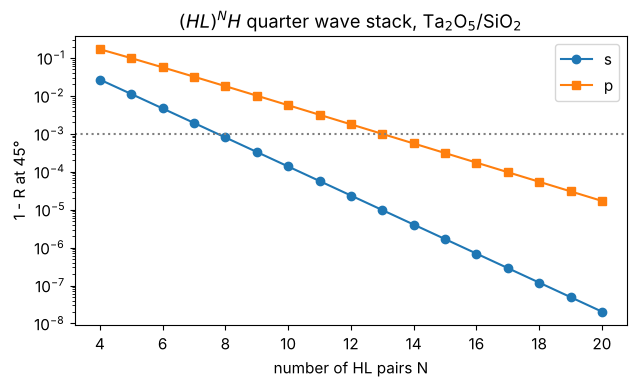

In [2]:
wl = 1.064e-3  # mm
a45 = np.pi/4
Ag, SiO2, Ta2O5, fused_silica = 0.1 + 7.0j, 1.45, 2.09, 1.4496

def quarter_wave_stack(pairs, angle=a45, wavelength=wl):
    # (HL)^N H from the air side
    H = Layer.quarter_wave(Ta2O5, wavelength, angle=angle, label="H")
    L = Layer.quarter_wave(SiO2, wavelength, angle=angle, label="L")
    return Coating([H, L]*pairs + [H], substrate=fused_silica)

H45 = quarter_wave_stack(1).layers[0]
print("quarter waves at 45°: H {:.1f} nm (normal incidence {:.1f} nm), L {:.1f} nm".format(
    H45.thickness*1e6, wl/(4*Ta2O5)*1e6, quarter_wave_stack(1).layers[1].thickness*1e6))

pairs = np.arange(4, 21)
R = np.array([[quarter_wave_stack(N).power(a45, 1.0, wavelength=wl)["R_" + pol] for pol in "sp"]
              for N in pairs])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(pairs, 1 - R[:, 0], "o-", label="s")
ax.semilogy(pairs, 1 - R[:, 1], "s-", label="p")
ax.axhline(1e-3, color="0.5", ls=":")
ax.set_xlabel("number of HL pairs N"), ax.set_ylabel("1 - R at 45°")
ax.set_title("$(HL)^N H$ quarter wave stack, Ta$_2$O$_5$/SiO$_2$")
ax.legend()
plt.tight_layout()
N_pairs = int(pairs[np.argmax(1 - R[:, 1] < 1e-3)])
print("N = {} pairs reach R_p > 99.9 % at 45°".format(N_pairs))

At oblique incidence the index contrast of the layers is larger for s
($n\cos\theta$) than for p ($n/\cos\theta$), so p needs more pairs for the
same reflectance. We take the smallest stack that reflects more than
99.9 % of p at 45°:

silver               R_s = 0.9944, R_p = 0.9888, loss (unpolarized) 0.84%
protected silver     R_s = 0.9902, R_p = 0.9864, loss (unpolarized) 1.17%
quarter wave stack   R_s = 1.0000, R_p = 0.9990, loss (unpolarized) 0.05%


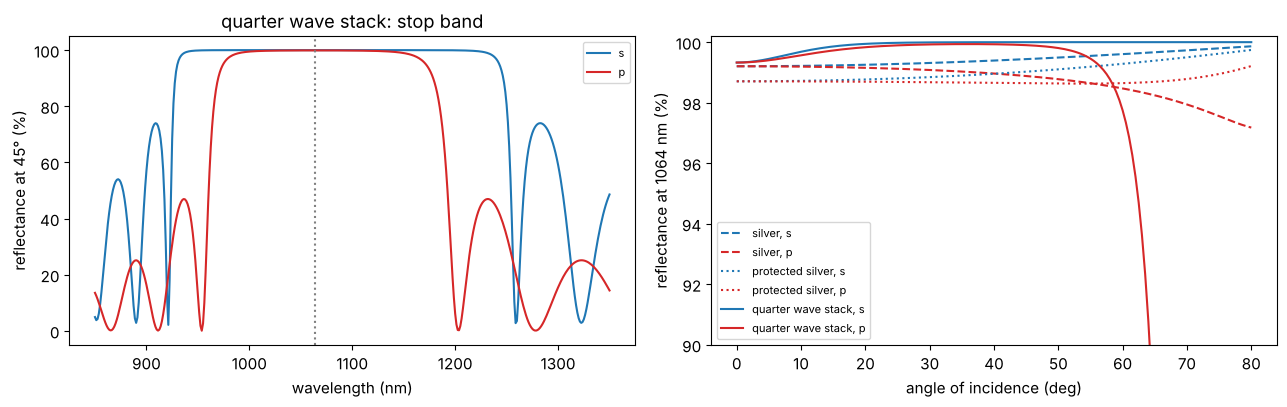

In [3]:
mirrors = {
    "silver": Coating([], substrate=Ag),
    "protected silver": Coating([Layer(SiO2, 100e-6, label="SiO2")], substrate=Ag),
    "quarter wave stack": quarter_wave_stack(N_pairs),
}

wavelengths = np.linspace(0.85e-3, 1.35e-3, 401)
theta = np.radians(np.linspace(0, 80, 161))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
stack = mirrors["quarter wave stack"]
for pol, color in (("s", "C0"), ("p", "C3")):
    R_wl = [stack.power(a45, 1.0, wavelength=w)["R_" + pol] for w in wavelengths]
    axes[0].plot(wavelengths*1e6, 100*np.array(R_wl), color=color, label=pol)
axes[0].axvline(1064, color="0.5", ls=":")
axes[0].set_xlabel("wavelength (nm)"), axes[0].set_ylabel("reflectance at 45° (%)")
axes[0].set_title("quarter wave stack: stop band")
for (name, c), ls in zip(mirrors.items(), ("--", ":", "-")):
    p = c.power(theta, 1.0, wavelength=wl)
    for pol, color in (("s", "C0"), ("p", "C3")):
        axes[1].plot(np.degrees(theta), 100*p["R_" + pol], ls=ls, color=color,
                     label="{}, {}".format(name, pol))
axes[1].set_ylim(90, 100.2)
axes[1].set_xlabel("angle of incidence (deg)"), axes[1].set_ylabel("reflectance at 1064 nm (%)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
for name, c in mirrors.items():
    p = c.power(a45, 1.0, wavelength=wl)
    print("{:20s} R_s = {:.4f}, R_p = {:.4f}, loss (unpolarized) {:.2%}".format(
        name, p["R_s"], p["R_p"], 1 - (p["R_s"] + p["R_p"])/2))

The p stop band is narrower than the s stop band, and with the angle of
incidence the stop band moves to shorter wavelengths, so the p reflectance
of the stack drops beyond about 60°. The silver mirrors absorb about one
percent, which matters for high power lasers (heating, damage), while the
dielectric stack (of lossless materials here) only lets 0.05 % through
into the substrate.

## 2. Retardance and the Goos–Hänchen shift

The phase difference between p and s on reflection is the retardance of
the mirror,

$$\delta(\theta) = \arg\frac{r_p(\theta)}{r_s(\theta)},$$

with the amplitude coefficients of `Coating.amplitudes()` (ratios of the
tangential field components, so that $\delta = 0$ at normal incidence). A
phase that varies with the angle of incidence also displaces a reflected
beam: the **Goos–Hänchen shift** of a beam with the reflection phase
$\varphi(\theta)$ is, perpendicular to the beam (Artmann's formula),

$$D = -\frac{\lambda}{2\pi}\frac{d\varphi}{d\theta},$$

and the s and p beams are displaced by different amounts,
$D_p - D_s = -\frac{\lambda}{2\pi}\,\frac{d\delta}{d\theta}$. For a metal
mirror $D$ is a few hundredths of a wavelength; in a dielectric stack the
light penetrates several layers, and $D$ is of the order of the penetration
depth.

silver               45°: retardance  +11.5°, D_s = +0.032 wl, D_p = -0.063 wl
protected silver     45°: retardance  +30.6°, D_s = +0.197 wl, D_p = -0.053 wl
quarter wave stack   45°: retardance   -0.0°, D_s = +0.101 wl, D_p = +0.262 wl


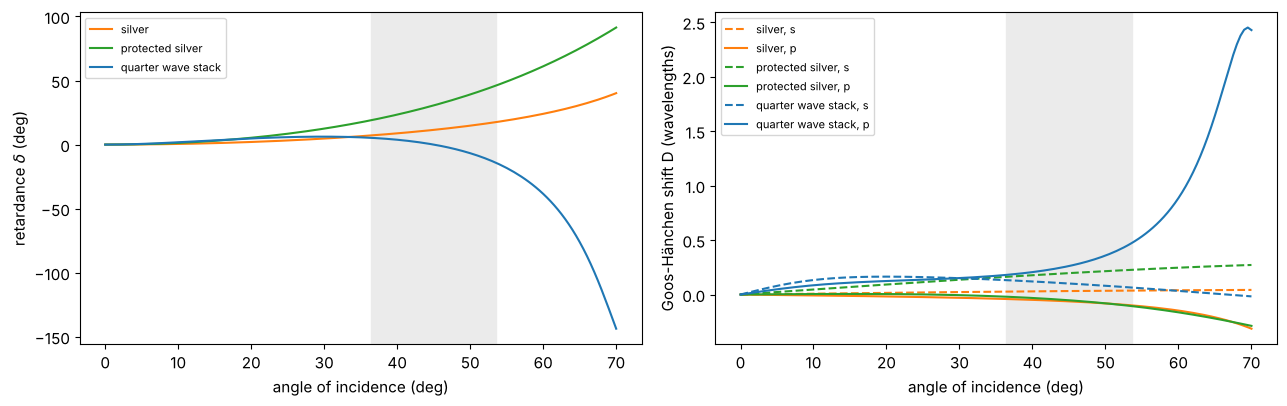

In [4]:
def phases(coating, theta, wavelength=wl):
    r_s, r_p = coating.amplitudes(np.cos(theta), 1.0, None, wavelength)[:2]
    return np.unwrap(np.angle(r_s)), np.unwrap(np.angle(r_p))

def goos_haenchen(coating, theta, wavelength=wl, h=1e-5):
    # Artmann: D = -lambda/(2 pi) dphi/dtheta for s and p (central difference of the phase)
    r_1 = coating.amplitudes(np.cos(theta - h), 1.0, None, wavelength)[:2]
    r_2 = coating.amplitudes(np.cos(theta + h), 1.0, None, wavelength)[:2]
    return [-wavelength/(2*np.pi)*np.angle(b/a)/(2*h) for a, b in zip(r_1, r_2)]

theta = np.radians(np.linspace(0, 70, 141))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for (name, c), color in zip(mirrors.items(), ("C1", "C2", "C0")):
    phi_s, phi_p = phases(c, theta)
    axes[0].plot(np.degrees(theta), np.degrees(np.angle(np.exp(1j*(phi_p - phi_s)))), color=color,
                 label=name)
    D_s, D_p = goos_haenchen(c, theta)
    axes[1].plot(np.degrees(theta), D_s/wl, color=color, ls="--", label=name + ", s")
    axes[1].plot(np.degrees(theta), D_p/wl, color=color, label=name + ", p")
axes[0].set_ylabel("retardance $\\delta$ (deg)")
axes[1].set_ylabel("Goos-Hänchen shift D (wavelengths)")
for ax in axes:
    ax.axvspan(45 - 8.6, 45 + 8.6, color="0.92", zorder=0)
    ax.set_xlabel("angle of incidence (deg)")
    ax.legend(fontsize=8)
plt.tight_layout()
for name, c in mirrors.items():
    D_s, D_p = goos_haenchen(c, np.array([a45]))
    r_s, r_p = c.amplitudes(np.cos(a45), 1.0, None, wl)[:2]
    print("{:20s} 45°: retardance {:+6.1f}°, D_s = {:+.3f} wl, D_p = {:+.3f} wl".format(
        name, np.degrees(np.angle(r_p/r_s))[()], D_s[0]/wl, D_p[0]/wl))

At 45° the quarter wave stack has no retardance (both $r_s$ and $r_p$ are
real there), but the retardance changes quickly with the angle of
incidence, and the Goos–Hänchen shifts of s and p are several times
larger than those of silver. The protected silver mirror has a large
retardance even at 45°. The grey band is the range of angles in a beam of
NA 0.15 centred on 45°, used in section 3.

### A phase compensated design

The retardance over an angle range can be reduced with a few non quarter
wave layers on top of the stack (the reflectance comes from the stack
underneath). We add three layers, L H L from the air side, and optimize
their thicknesses (in units of the 45° quarter waves) for the smallest
rms retardance between 36.4° and 53.6°, from many random starts:

In [5]:
NA_fold = 0.15
cone = np.radians(45 + np.degrees(np.arcsin(NA_fold))*np.linspace(-1, 1, 19))
qw_H, qw_L = (l.thickness for l in stack.layers[:2])

def compensated(f):
    # top layers L H L (air side first) with thicknesses f in quarter waves at 45°
    top = [Layer(SiO2, f[0]*qw_L, label="L"), Layer(Ta2O5, f[1]*qw_H, label="H"),
           Layer(SiO2, f[2]*qw_L, label="L")]
    return Coating(top + stack.layers, substrate=fused_silica)

def rms_retardance(f):
    r_s, r_p = compensated(f).amplitudes(np.cos(cone), 1.0, None, wl)[:2]
    return np.sqrt(np.mean(np.angle(r_p/r_s)**2))

rng = np.random.default_rng(1)
runs = [minimize(rms_retardance, rng.uniform(0, 4, 3), method="L-BFGS-B", bounds=[(0, 4)]*3)
        for _ in range(30)]
best = min(runs, key=lambda r: r.fun)
mirrors["phase compensated stack"] = compensated(best.x)
print("top layers (quarter waves at 45°): L {:.3f}, H {:.3f}, L {:.3f}".format(*best.x))
print("thicknesses: " + ", ".join("{} {:.1f} nm".format(l.label, l.thickness*1e6)
                                  for l in mirrors["phase compensated stack"].layers[:3]))
for name in ("quarter wave stack", "phase compensated stack"):
    c = mirrors[name]
    r_s, r_p = c.amplitudes(np.cos(cone), 1.0, None, wl)[:2]
    print("{:24s} retardance in the cone: max {:5.2f}°, rms {:5.2f}°; min R_s {:.4f}, min R_p {:.4f}"
          .format(name, np.degrees(np.abs(np.angle(r_p/r_s))).max(),
                  np.degrees(rms_retardance(best.x) if "comp" in name else
                             np.sqrt(np.mean(np.angle(r_p/r_s)**2))),
                  np.min(np.abs(r_s)**2), np.min(np.abs(r_p)**2)))

top layers (quarter waves at 45°): L 0.868, H 1.218, L 1.237
thicknesses: L 182.4 nm, H 164.7 nm, L 259.9 nm
quarter wave stack       retardance in the cone: max 14.46°, rms  6.19°; min R_s 1.0000, min R_p 0.9960
phase compensated stack  retardance in the cone: max  2.11°, rms  0.96°; min R_s 1.0000, min R_p 0.9973


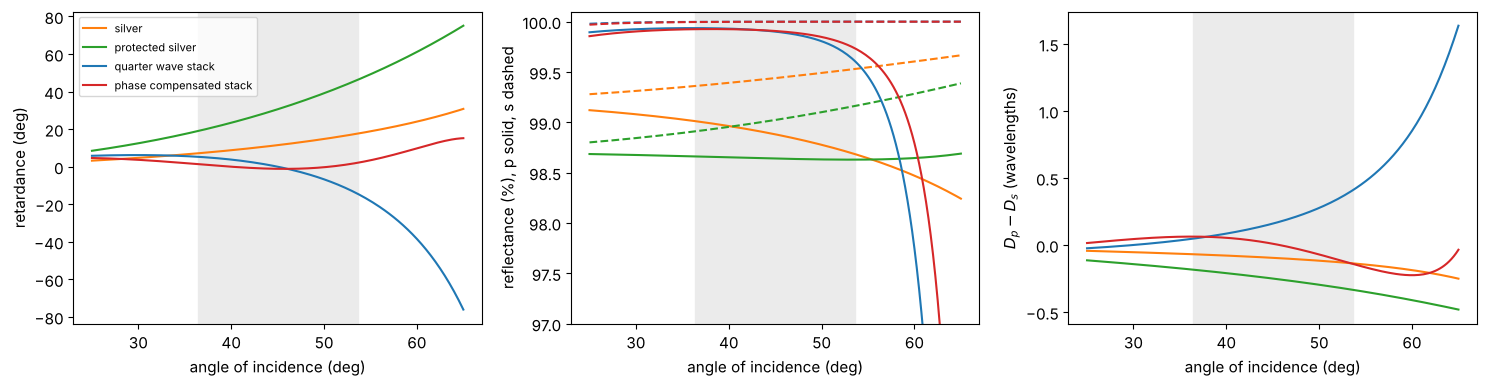

In [6]:
theta = np.radians(np.linspace(25, 65, 161))
colors = {"silver": "C1", "protected silver": "C2", "quarter wave stack": "C0",
          "phase compensated stack": "C3"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, c in mirrors.items():
    phi_s, phi_p = phases(c, theta)
    p = c.power(theta, 1.0, wavelength=wl)
    D_s, D_p = goos_haenchen(c, theta)
    axes[0].plot(np.degrees(theta), np.degrees(np.angle(np.exp(1j*(phi_p - phi_s)))),
                 color=colors[name], label=name)
    axes[1].plot(np.degrees(theta), 100*p["R_p"], color=colors[name])
    axes[1].plot(np.degrees(theta), 100*p["R_s"], color=colors[name], ls="--")
    axes[2].plot(np.degrees(theta), (D_p - D_s)/wl, color=colors[name])
axes[0].set_ylabel("retardance (deg)"), axes[0].legend(fontsize=8)
axes[1].set_ylabel("reflectance (%), p solid, s dashed"), axes[1].set_ylim(97, 100.1)
axes[2].set_ylabel("$D_p - D_s$ (wavelengths)")
for ax in axes:
    ax.axvspan(np.degrees(cone[0]), np.degrees(cone[-1]), color="0.92", zorder=0)
    ax.set_xlabel("angle of incidence (deg)")
plt.tight_layout()

The compensating layers flatten the retardance in the design range from
6° to about 1° rms, and with it the difference of the Goos–Hänchen shifts
of s and p, while the p reflectance at the edge of the cone even rises a
little. (A real design would also check the tolerance to layer thickness
errors; see section 5 for the retardance over the wavelength.)

## 3. The mirror in a converging beam

A collimated beam of 3 mm diameter is focused by an ideal lens with
$f = 10$ mm (NA 0.15), and the mirror folds the converging beam by 90°
halfway to the focus, as in a compact focusing head. The fold is set up
with coordinate breaks: the plane of incidence of the chief ray is the
$y$-$z$ plane, so $x$ polarization is s and $y$ polarization is p on the
axis. Rays in other parts of the pupil meet the mirror at angles between
36° and 54°, in planes of incidence that are tilted against the meridional
plane.

beam diameter 3.03 mm, image space NA 0.150


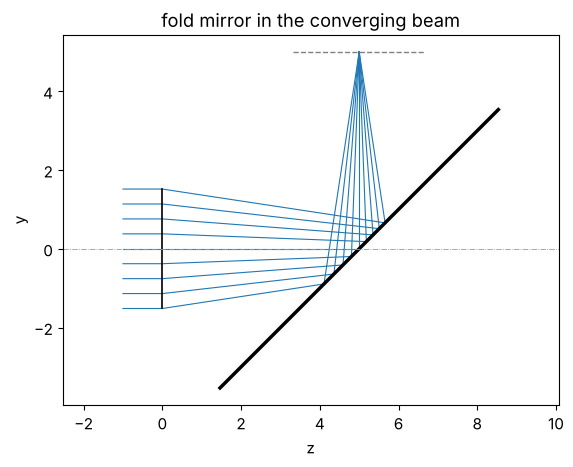

In [7]:
f_lens = 10.0
D_beam = 2*f_lens*np.tan(np.arcsin(NA_fold))
fold = System([IdealLens(f_lens, thickness=f_lens/2, semi_diameter=D_beam/2),
               CoordinateBreak(tilt=(a45, 0, 0)),
               Surface(mirror=True, semi_diameter=5.0),
               CoordinateBreak(tilt=(a45, 0, 0), thickness=-f_lens/2)], 0, wl)
MIRROR = 2  # index of the mirror surface, for coatings={MIRROR: coating}
print("beam diameter {:.2f} mm, image space NA {:.3f}".format(D_beam, NA_fold))
ax = fold.draw(n_rays=9)
ax.set_title("fold mirror in the converging beam")
ax.set_aspect("equal")

### Jones pupils of the coated fold

`trace_pupil_polarization()` evaluates every coating at the local angle of
incidence of every ray; `PolarizedBundle.jones()` gives the Jones matrices
on the aplanatic bases of the input and output rays, and
`jones_pupil.decompose()` their linear diattenuation and retardance
(magnitude in colour, orientation as ticks). The constant part of the
retardance is the 45° value of section 2; across the pupil it changes along
$P_y$ (the angle of incidence) and its axis rotates along $P_x$ (the plane
of incidence).

silver                   retardance over the pupil: 0.0198 ... 0.0490 waves
protected silver         retardance over the pupil: 0.0526 ... 0.1285 waves
quarter wave stack       retardance over the pupil: 0.0000 ... 0.0402 waves
phase compensated stack  retardance over the pupil: 0.0000 ... 0.0059 waves


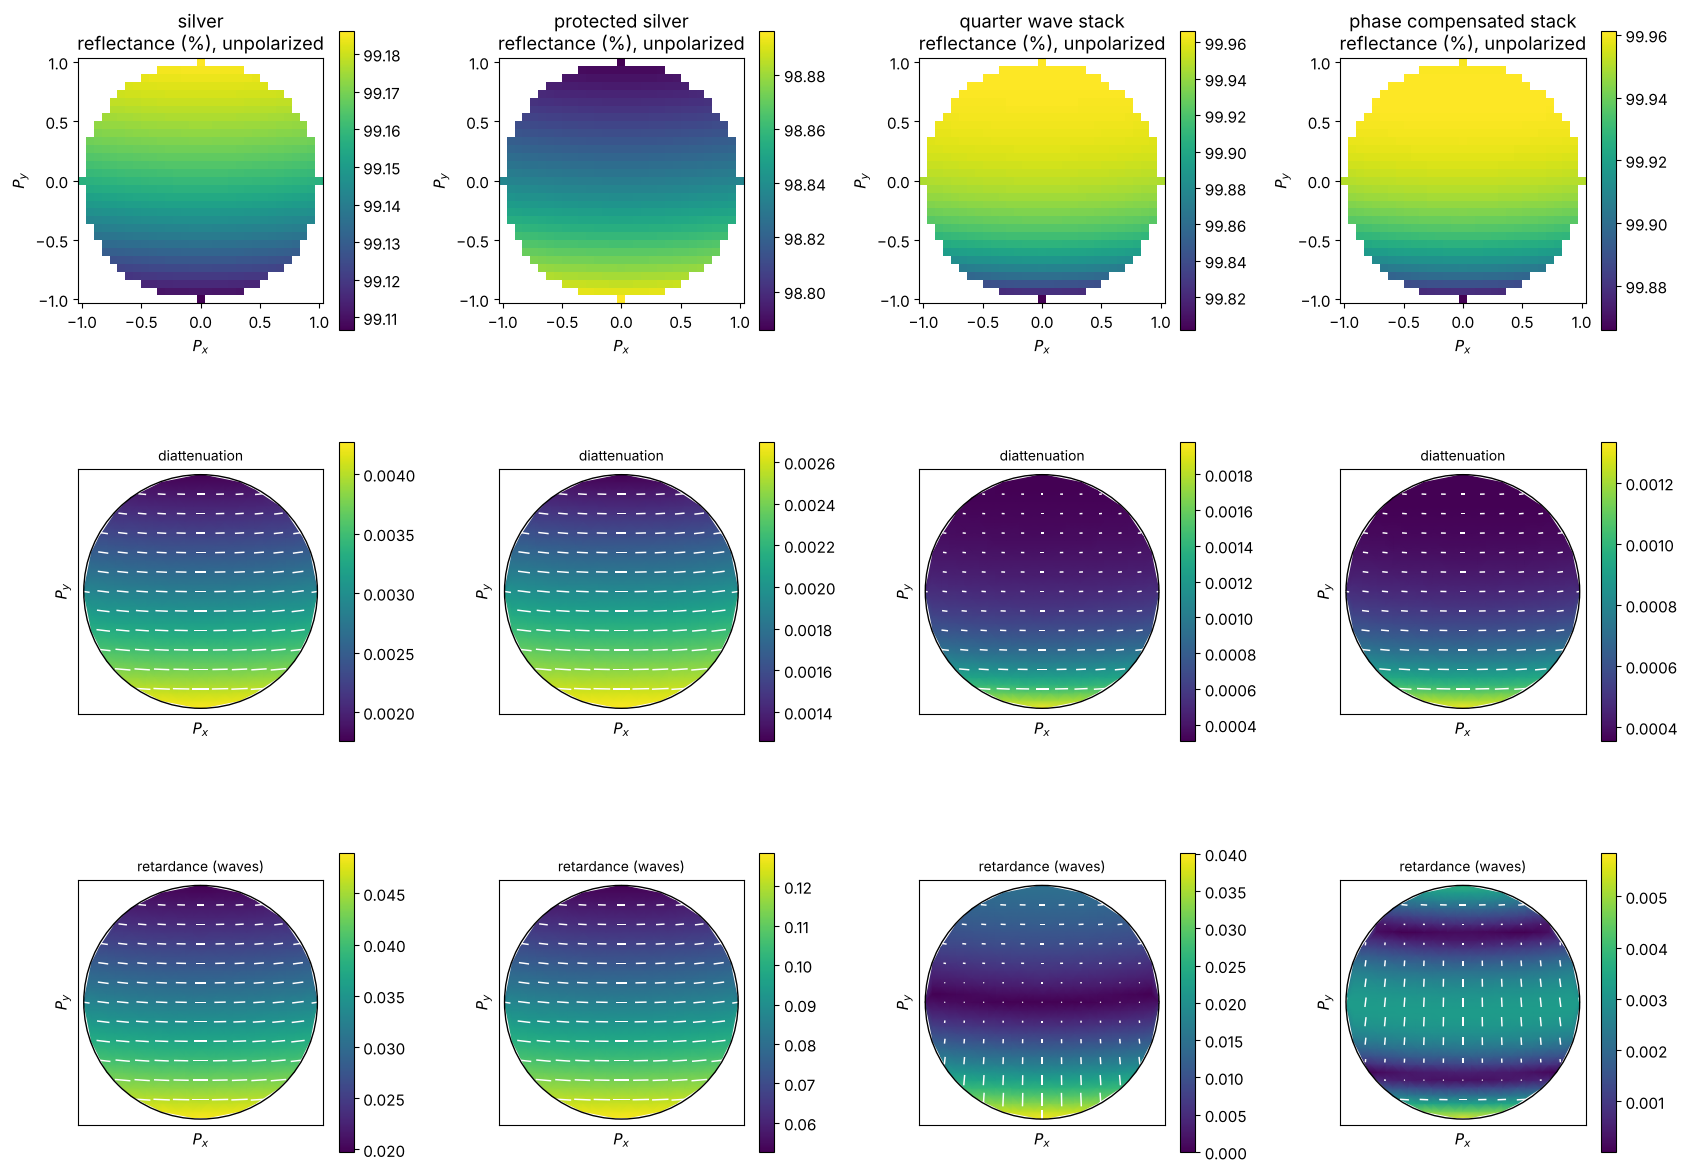

In [8]:
p = np.linspace(-1, 1, 31)
PX, PY = np.meshgrid(p, p)
inside = PX**2 + PY**2 <= 1
traced = {name: fold.trace_pupil_polarization(0.0, PX[inside], PY[inside], coatings={MIRROR: c})
          for name, c in mirrors.items()}

fig, axes = plt.subplots(3, 4, figsize=(17, 12.5))
for col, (name, t) in enumerate(traced.items()):
    parts = jp.decompose(t.jones())
    d, g = parts["diattenuation"], parts["retardance"]
    xy = (PX[inside], PY[inside])
    R_map = np.full(PX.shape, np.nan)
    R_map[inside] = t.transmittance()
    im = axes[0, col].pcolormesh(p, p, 100*R_map, shading="auto", cmap="viridis")
    axes[0, col].set_aspect("equal"), axes[0, col].set_title(name + "\nreflectance (%), unpolarized")
    plt.colorbar(im, ax=axes[0, col], shrink=0.8)
    plot_orientation(xy + (d[0] + 1j*d[1],), ax=axes[1, col], title="diattenuation")
    plot_orientation(xy + (g[0] + 1j*g[1],), ax=axes[2, col], title="retardance (waves)")
for ax in axes.flat:
    ax.set_xlabel("$P_x$"), ax.set_ylabel("$P_y$")
plt.tight_layout()
for name, t in traced.items():
    g = jp.decompose(t.jones())["retardance"]
    mag = np.hypot(g[0], g[1])
    print("{:24s} retardance over the pupil: {:.4f} ... {:.4f} waves".format(name, mag.min(), mag.max()))

The quarter wave stack has zero retardance on the axis but a strong
gradient along $P_y$, which changes sign through the centre (the
retardance passes through zero at 45°, so its orientation flips between s
and p). The compensated stack keeps it small everywhere; the silver mirrors
add a large constant retardance with a gentler gradient. The diattenuation
of the dielectric stacks is smaller than that of silver; it grows towards
$P_y = -1$, where the angle of incidence is largest and the p reflectance
starts to drop.

## 4. The vectorial focus behind the fold

`System.vectorial_focus(x, y, E_in=...)` interpolates the output fields of
the traced rays (complex 3D vectors in the image frame, including the
optical path difference, here zero) on the plane wave grid of the window
$x, y$ and sums them. With `normalization="peak"` the intensity is relative
to the peak of an ideal, lossless focus of the same NA. Behind the mirror
the light travels in $-z$ of the image frame; the field is still given in
the image frame.

**s and p foci separate.** A phase that changes linearly with the angle of
incidence is a wavefront tilt in the image space, so the focus of the
reflected beam is displaced by the Goos–Hänchen shift $D$ of section 2,
along the image frame's $y$ axis (in the plane of incidence). We compare the
centroids of the s ($x$) and p ($y$) polarized foci with Artmann's
formula, relative to the perfect mirror (`None`):

In [9]:
x = grid1d(-24*wl, 24*wl, 256)
X, Y = np.meshgrid(x, x)
S_POL, P_POL, D45 = (1, 0), (0, 1), (1, 1)

def focus(coating, E_in, system=fold, x=x, N=64):
    return system.vectorial_focus(x, x, field=0.0, E_in=E_in, N=N, coatings={MIRROR: coating})

def centroid(E, X=X, Y=Y, NA=NA_fold):
    # centroid of the intensity inside the Airy disk (the tails wrap around the FFT window)
    I = np.sum(np.abs(E)**2, axis=-1)*(np.hypot(X, Y) < 0.61*wl/NA)
    return np.sum(I*X)/np.sum(I), np.sum(I*Y)/np.sum(I)

ref = {pol: centroid(focus(None, E_in)) for pol, E_in in (("s", S_POL), ("p", P_POL))}
print("{:24s} {:>9s} {:>9s} {:>9s} {:>9s} {:>9s}".format("(wavelengths)", "y_s", "D_s", "y_p", "D_p",
                                                      "y_p - y_s"))
shifts = {}
for name, c in mirrors.items():
    y_s = centroid(focus(c, S_POL))[1] - ref["s"][1]
    y_p = centroid(focus(c, P_POL))[1] - ref["p"][1]
    D_s, D_p = goos_haenchen(c, np.array([a45]))
    shifts[name] = y_s, y_p
    print("{:24s} {:+9.3f} {:+9.3f} {:+9.3f} {:+9.3f} {:+9.3f}".format(
        name, y_s/wl, D_s[0]/wl, y_p/wl, D_p[0]/wl, (y_p - y_s)/wl))

(wavelengths)                  y_s       D_s       y_p       D_p y_p - y_s


silver                      +0.032    +0.032    -0.064    -0.063    -0.096


protected silver            +0.196    +0.197    -0.054    -0.053    -0.250


quarter wave stack          +0.101    +0.101    +0.270    +0.262    +0.169


phase compensated stack     +0.637    +0.646    +0.636    +0.657    -0.000


The traced foci move by the Goos–Hänchen shifts, to within a few percent
that come from the curvature of the phase over the cone (Artmann's formula
is the derivative at 45°; see section 6 for smaller NA). For the quarter
wave stack the s and p foci are 0.17 wavelengths apart, which a 45° or
unpolarized beam sees as a slightly elongated spot. The compensated stack
brings them together: both move by about 0.64 wavelengths, a common
displacement of the focus that the alignment of the head takes out, and
no longer a polarization effect.

**Depolarization.** For a beam linearly polarized at 45° to the plane of
incidence, the retardance turns the polarization elliptical and rotates
it differently across the pupil. The light that a crossed analyzer behind
the focus would pass (the component perpendicular to the input
polarization, $|E_\perp|^2$), and the polarization extinction ratio over
the whole focus:

perfect mirror           peak 0.9944, cross polarized 5.62e-06 of the power, extinction ratio 177027:1, E_z 5.59e-03


silver                   peak 0.9852, cross polarized 1.08e-02 of the power, extinction ratio     91:1, E_z 5.59e-03
protected silver         peak 0.9767, cross polarized 7.39e-02 of the power, extinction ratio     12:1, E_z 5.59e-03


quarter wave stack       peak 0.9920, cross polarized 1.83e-03 of the power, extinction ratio    541:1, E_z 5.58e-03


phase compensated stack  peak 0.9920, cross polarized 5.96e-05 of the power, extinction ratio  16697:1, E_z 5.58e-03


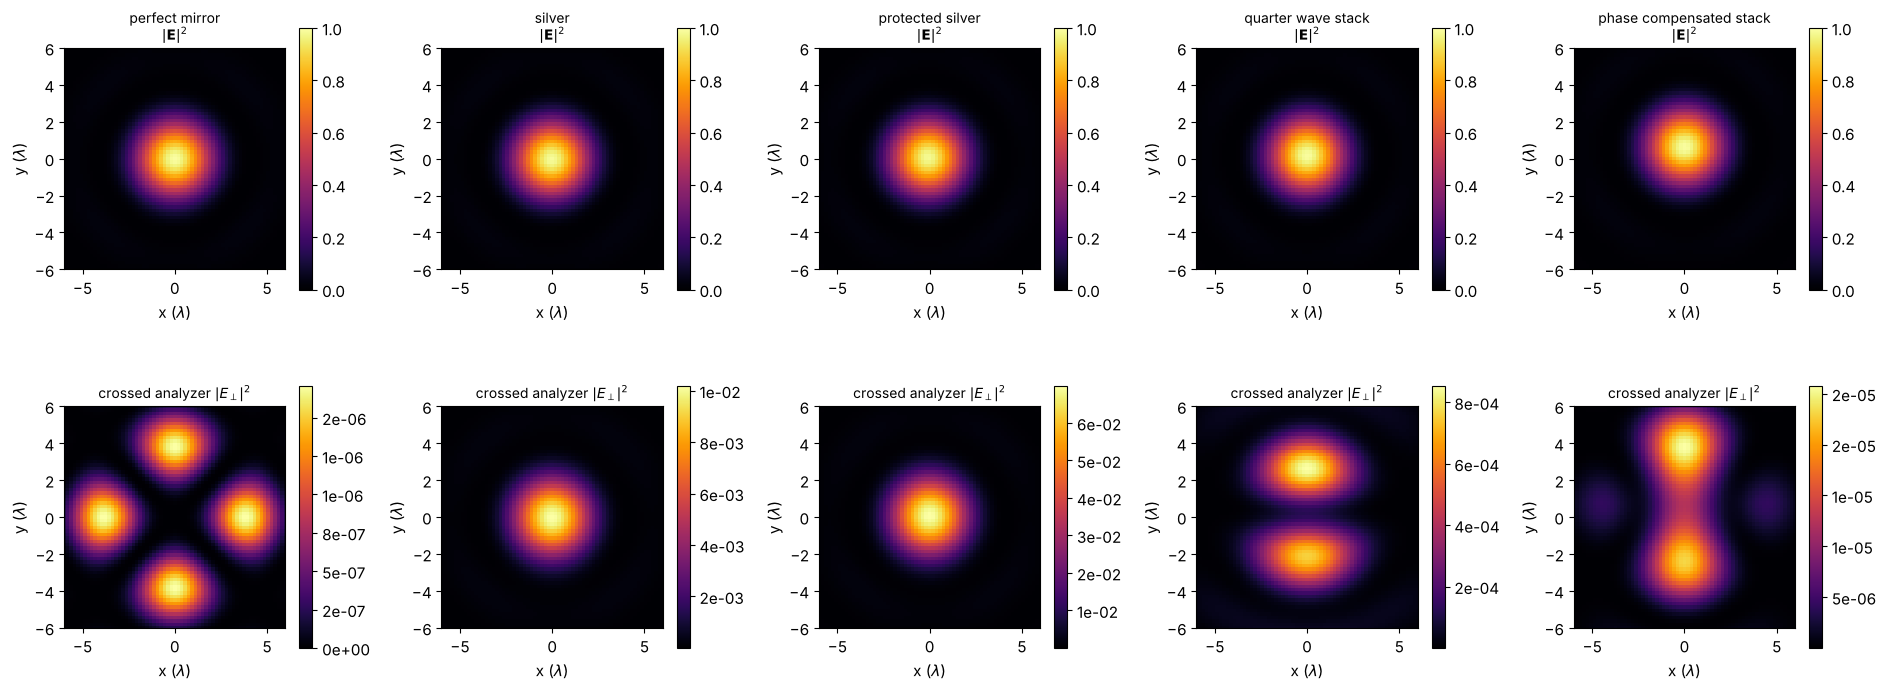

In [10]:
e_co, e_cross = np.array([1, 1])/np.sqrt(2), np.array([-1, 1])/np.sqrt(2)
names = ["perfect mirror"] + list(mirrors)
fig, axes = plt.subplots(2, 5, figsize=(19, 7.5))
lim = 6
for col, name in enumerate(names):
    E = focus(mirrors.get(name), D45)
    I = np.sum(np.abs(E)**2, axis=-1)
    I_cross = np.abs(E[..., :2] @ e_cross)**2
    I_co = np.abs(E[..., :2] @ e_co)**2
    print("{:24s} peak {:.4f}, cross polarized {:.2e} of the power, extinction ratio {:6.0f}:1, "
          "E_z {:.2e}".format(name, I.max(), I_cross.sum()/I.sum(), I_co.sum()/I_cross.sum(),
                              np.sum(np.abs(E[..., 2])**2)/I.sum()))
    im = axes[0, col].pcolormesh(x/wl, x/wl, I, shading="auto", cmap="inferno", vmin=0, vmax=1)
    axes[0, col].set_title(name + "\n$|\\mathbf{E}|^2$", fontsize=10)
    plt.colorbar(im, ax=axes[0, col], shrink=0.8)
    im = axes[1, col].pcolormesh(x/wl, x/wl, I_cross, shading="auto", cmap="inferno")
    axes[1, col].set_title("crossed analyzer $|E_\\perp|^2$", fontsize=10)
    plt.colorbar(im, ax=axes[1, col], shrink=0.8, format="%.0e")
for ax in axes.flat:
    ax.set_xlim(-lim, lim), ax.set_ylim(-lim, lim), ax.set_aspect("equal")
    ax.set_xlabel("x ($\\lambda$)"), ax.set_ylabel("y ($\\lambda$)")
plt.tight_layout()

The perfect mirror leaves only the small geometric depolarization of a
focused beam (a four leaf pattern, from the rotation of the field of the
oblique plane waves). The constant retardance of the silver mirrors sends
light into the crossed polarization over the whole spot, most for
protected silver with its retardance of about 30°. The quarter wave stack
has no retardance on the axis, so its cross polarized light comes from
the retardance gradient: it is antisymmetric across the pupil and leaves
a two lobed pattern with a zero in the centre. The compensated stack
reduces it further.

## 5. Circular polarization in front of a high NA objective

For laser cutting and drilling, the beam is often circularly polarized,
so that the absorption at the cut front (which depends on the
polarization) is the same in all cutting directions. A fold mirror in the
collimated beam in front of the focusing objective reflects all rays at
45°: its retardance is a uniform phase plate that turns the circular
polarization elliptical. Behind a high NA objective the focus of linearly
polarized light is elongated along the polarization, so the ellipticity
shows up in the shape of the focal spot.

The system: the collimated beam is folded first and then focused by an
ideal lens with NA 0.8.

The mirror sees the collimated beam at 45° for every ray, and the objective
bends the reflected rays by up to $\arcsin 0.8 = 53°$ towards the focus,
where the vectorial effects come from (the drawing shows the meridional
section; the image plane is the dashed line):

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


beam diameter 5.33 mm, focal length 2.0 mm, NA 0.80 (marginal ray at 53.1°)


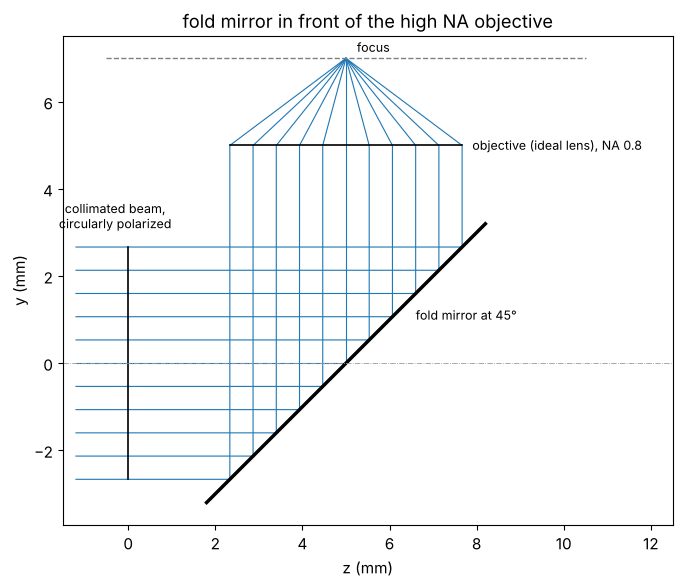

In [11]:
NA_hi, f_hi = 0.8, 2.0
a_hi = f_hi*np.tan(np.arcsin(NA_hi))
high_na = System([Surface(thickness=5.0, semi_diameter=a_hi),
                  CoordinateBreak(tilt=(a45, 0, 0)),
                  Surface(mirror=True, semi_diameter=1.2*np.sqrt(2)*a_hi),
                  CoordinateBreak(tilt=(a45, 0, 0), thickness=-5.0),
                  IdealLens(f_hi, thickness=-f_hi, semi_diameter=a_hi)], 0, wl)
print("beam diameter {:.2f} mm, focal length {:.1f} mm, NA {:.2f} (marginal ray at {:.1f}°)".format(
    2*a_hi, f_hi, NA_hi, np.degrees(np.arcsin(NA_hi))))

fig, ax = plt.subplots(figsize=(7, 6))
high_na.draw(ax=ax, n_rays=11)
ax.set_aspect("equal")
ax.set_xlabel("z (mm)"), ax.set_ylabel("y (mm)")
for text, xy, ha in (("collimated beam,\ncircularly polarized", (-0.3, 3.1), "center"),
                     ("fold mirror at 45°", (6.6, 1.0), "left"),
                     ("objective (ideal lens), NA 0.8", (7.9, 4.9), "left"),
                     ("focus", (5.25, 7.15), "left")):
    ax.annotate(text, xy, ha=ha, fontsize=9)
ax.set_xlim(-2.5, 13.5)
ax.set_title("fold mirror in front of the high NA objective")
plt.tight_layout()

perfect mirror           reflected beam: S3 = +1.000 (ellipticity angle +45.0°); spot 0.502 x 0.502 wl (ratio 1.000, long axis at  45.0°), peak 0.819


silver                   reflected beam: S3 = +0.980 (ellipticity angle +39.3°); spot 0.518 x 0.492 wl (ratio 1.054, long axis at 135.3°), peak 0.813
protected silver         reflected beam: S3 = +0.861 (ellipticity angle +29.7°); spot 0.532 x 0.473 wl (ratio 1.124, long axis at 135.1°), peak 0.810


quarter wave stack       reflected beam: S3 = +1.000 (ellipticity angle +45.0°); spot 0.503 x 0.502 wl (ratio 1.000, long axis at   0.1°), peak 0.819


phase compensated stack  reflected beam: S3 = +1.000 (ellipticity angle +44.4°); spot 0.504 x 0.500 wl (ratio 1.008, long axis at  44.7°), peak 0.819


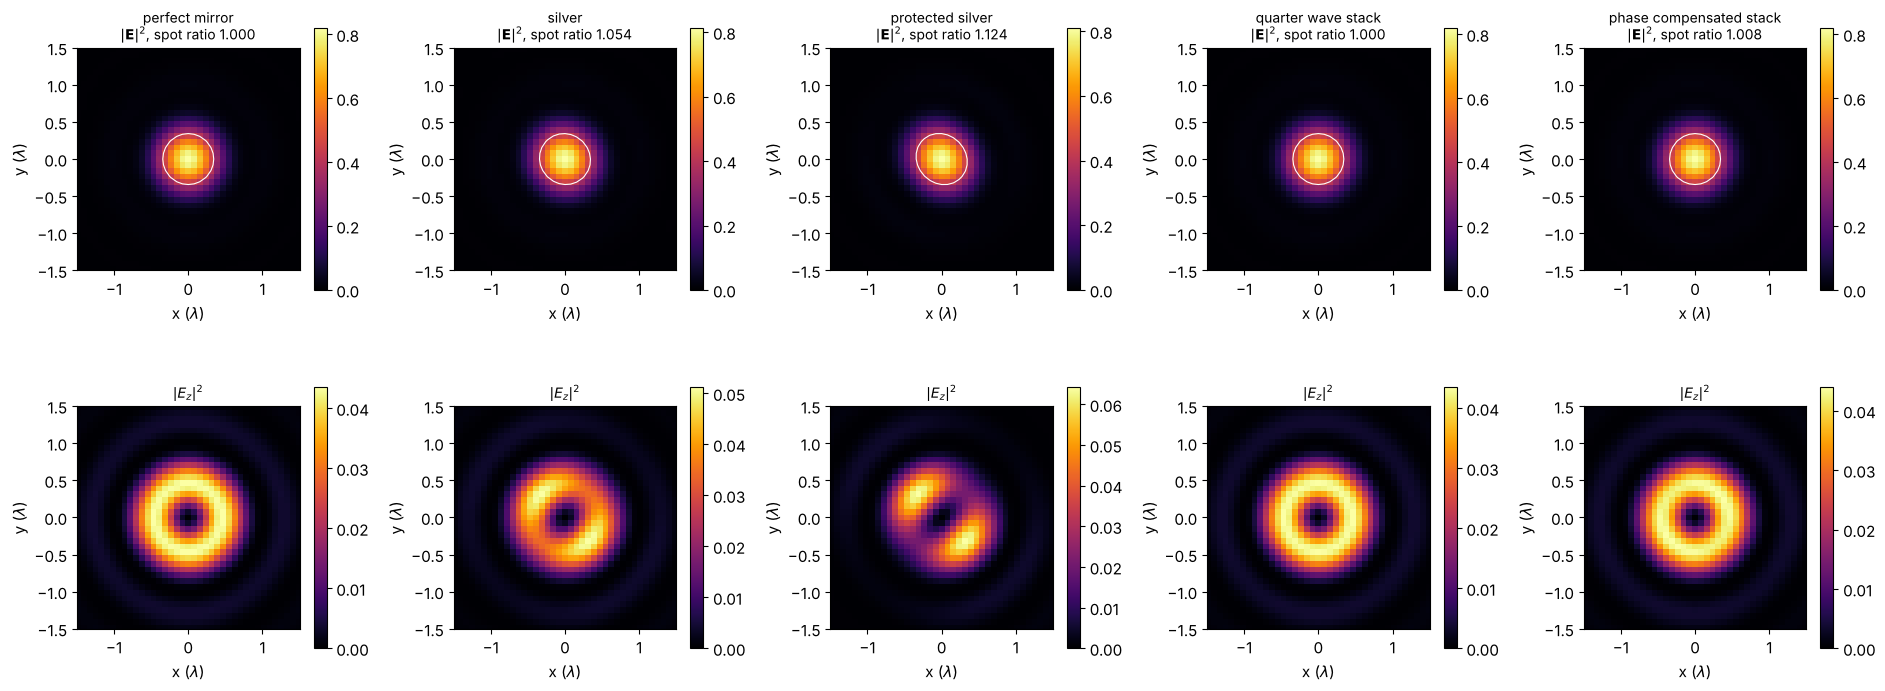

In [12]:
x_hi = grid1d(-10*wl, 10*wl, 256)
X_hi, Y_hi = np.meshgrid(x_hi, x_hi)
circular = (1, 1j)

def stokes(J, E_in):
    # normalized Stokes vector of the reflected chief ray
    E = J @ (np.asarray(E_in)/np.linalg.norm(E_in))
    S0 = np.sum(np.abs(E)**2)
    return np.array([np.abs(E[0])**2 - np.abs(E[1])**2, 2*np.real(np.conj(E[0])*E[1]),
                     2*np.imag(np.conj(E[0])*E[1])])/S0

def spot_axes(I, threshold=0.05):
    # 1/e^2-like widths from the second moments of the intensity above the threshold
    w = np.where(I > threshold*I.max(), I, 0)
    c = [np.sum(w*a*b)/np.sum(w) for a, b in ((X_hi, X_hi), (X_hi, Y_hi), (Y_hi, Y_hi))]
    ev, evec = np.linalg.eigh([[c[0], c[1]], [c[1], c[2]]])
    return 2*np.sqrt(ev), np.degrees(np.arctan2(evec[1, 1], evec[0, 1])) % 180

fig, axes = plt.subplots(2, 5, figsize=(19, 7.5))
for col, name in enumerate(names):
    c = mirrors.get(name)
    J = high_na.trace_pupil_polarization(0.0, [0.0], [0.0], coatings={MIRROR: c}).jones()[0]
    s = stokes(J, circular)
    E = focus(c, circular, system=high_na, x=x_hi)
    I = np.sum(np.abs(E)**2, axis=-1)
    (w_min, w_max), angle = spot_axes(I)
    print("{:24s} reflected beam: S3 = {:+.3f} (ellipticity angle {:+5.1f}°); spot {:.3f} x {:.3f} "
          "wl (ratio {:.3f}, long axis at {:5.1f}°), peak {:.3f}".format(
              name, s[2], np.degrees(np.arcsin(s[2]))/2, w_max/wl, w_min/wl, w_max/w_min, angle,
              I.max()))
    im = axes[0, col].pcolormesh(x_hi/wl, x_hi/wl, I, shading="auto", cmap="inferno", vmin=0)
    axes[0, col].contour(x_hi/wl, x_hi/wl, I/I.max(), [0.5], colors="w", linewidths=0.8)
    axes[0, col].set_title("{}\n$|\\mathbf{{E}}|^2$, spot ratio {:.3f}".format(name, w_max/w_min),
                           fontsize=10)
    plt.colorbar(im, ax=axes[0, col], shrink=0.8)
    im = axes[1, col].pcolormesh(x_hi/wl, x_hi/wl, np.abs(E[..., 2])**2, shading="auto",
                                 cmap="inferno", vmin=0)
    axes[1, col].set_title("$|E_z|^2$", fontsize=10)
    plt.colorbar(im, ax=axes[1, col], shrink=0.8)
for ax in axes.flat:
    ax.set_xlim(-1.5, 1.5), ax.set_ylim(-1.5, 1.5), ax.set_aspect("equal")
    ax.set_xlabel("x ($\\lambda$)"), ax.set_ylabel("y ($\\lambda$)")
plt.tight_layout()

Behind the perfect mirror the polarization stays circular ($|S_3| = 1$,
with $S_3$ taken on the aplanatic basis of the reflected chief ray), and
the spot is round, with a ring of longitudinal field $E_z$ around the
axis. The 30° retardance of protected silver makes the beam elliptical
($S_3 = 0.86$), and the spot becomes elliptical too (12 % longer along
the major axis of the polarization ellipse), with the $E_z$ ring split
into two lobes; bare silver does the same, less strongly. Both dielectric
stacks have practically no retardance at 45° and 1064 nm.

How robust is that? Laser mirrors are often used at more than one
wavelength (Nd:YAG at 1064 nm, Yb lasers at 1030 nm). The retardance of
the stacks at 45° over the wavelength:

quarter wave stack       retardance at 1030 nm: +9.3°
phase compensated stack  retardance at 1030 nm: +0.3°


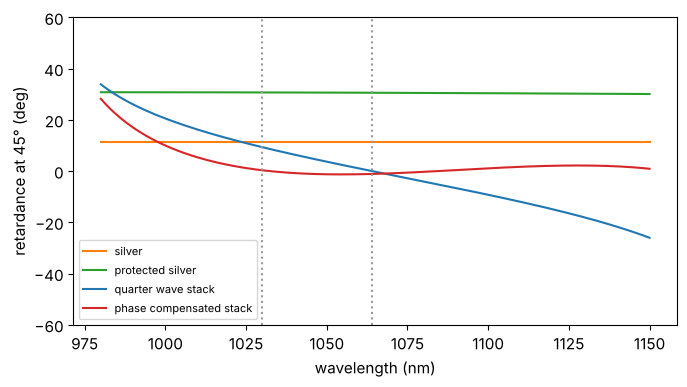

In [13]:
wls = np.linspace(0.98e-3, 1.15e-3, 171)
fig, ax = plt.subplots(figsize=(7, 4))
for name, c in mirrors.items():
    delta = [np.angle(np.divide(*c.amplitudes(np.cos(a45), 1.0, None, w)[1::-1]))
             for w in wls]
    ax.plot(wls*1e6, np.degrees(delta), color=colors[name], label=name)
for w in (1030, 1064):
    ax.axvline(w, color="0.6", ls=":")
ax.set_xlabel("wavelength (nm)"), ax.set_ylabel("retardance at 45° (deg)")
ax.set_ylim(-60, 60), ax.legend(fontsize=8)
plt.tight_layout()
for name in ("quarter wave stack", "phase compensated stack"):
    r_s, r_p = mirrors[name].amplitudes(np.cos(a45), 1.0, None, 1.030e-3)[:2]
    print("{:24s} retardance at 1030 nm: {:+.1f}°".format(name, np.degrees(np.angle(r_p/r_s))))

The retardance of the quarter wave stack changes steadily with the
wavelength and grows towards the edges of the stop band: at 1030 nm it is
already 9°, enough to spoil a circular polarization noticeably. The phase
compensating layers flatten the retardance over the wavelength as well
(the angle of incidence and the wavelength both act through the phase
thicknesses of the layers): 0.3° at 1030 nm. Metal mirrors change slowly
with the wavelength. Polarization critical beam paths therefore specify
the retardance of their mirrors at the operating wavelengths and angles.

## 6. Checks

**Richards–Wolf focus.** With a perfect mirror, the fold only mirrors the
geometry, and the focus must be that of the ideal lens alone. The traced
focus agrees with `propagators.vectorial_mansuripur()` for a uniform
circular pupil of the same NA (the sine of the marginal ray angle of the
ideal lens, $a/\sqrt{a^2 + f^2}$), which implements the Richards–Wolf
integral of an aplanatic lens. The remaining difference of a few
$10^{-3}$ comes from the pupil rim (the polygon of the rim rays against the
sharp circle of the reference) and shrinks with a larger window, i.e. a
finer sampling of the pupil. Behind the mirror the light travels in $-z$
of the image frame, so we compare $|E_x|$, which the fold leaves
unchanged.

In [14]:
unfolded = System([IdealLens(f_hi, thickness=f_hi, semi_diameter=a_hi)], 0, wl)
NA_true = a_hi/np.hypot(a_hi, f_hi)
k = 2*np.pi/wl
K_x, K_y = freq_grid(x_hi, x_hi, wavenumbers=True, normal_order=True)
pupil = (K_x**2 + K_y**2 < (k*NA_true)**2).astype(float)
S_z = np.sqrt(np.clip(1 - (K_x**2 + K_y**2)/k**2, 1e-12, None))
E_rw = vectorial_mansuripur(np.stack([inv_FT(pupil), 0*pupil], -1), x_hi, x_hi, 0.0, wl)[0]
E_rw /= np.abs(inv_FT(pupil/np.sqrt(S_z))).max()
E_lens = focus(None, S_POL, system=unfolded, x=x_hi, N=128)
E_fold = focus(None, S_POL, system=high_na, x=x_hi, N=128)
print("lens alone vs. Richards-Wolf: max |dE| = {:.1e}".format(np.abs(E_lens - E_rw).max()))
print("folded vs. lens alone: max ||E_x| - |E_x|| = {:.1e}".format(
    np.abs(np.abs(E_fold[..., 0]) - np.abs(E_lens[..., 0])).max()))
print("peak of the vectorial focus at NA {:.2f}: {:.4f} (E_z share {:.3f})".format(
    NA_true, np.sum(np.abs(E_rw)**2, -1).max(),
    np.sum(np.abs(E_rw[..., 2])**2)/np.sum(np.abs(E_rw)**2)))

lens alone vs. Richards-Wolf: max |dE| = 5.1e-03
folded vs. lens alone: max ||E_x| - |E_x|| = 1.7e-03
peak of the vectorial focus at NA 0.80: 0.8206 (E_z share 0.171)


**Chief ray.** The Jones matrix of the chief ray at the fold is diagonal in
s and p with the reflection coefficients of the coating at 45° (up to the
sign convention of the aplanatic output basis for light travelling in
$-z$), and the Goos–Hänchen shifts of section 4 follow Artmann's formula
more closely for a smaller NA, where the phase is closer to linear over
the cone:

In [15]:
for name, c in mirrors.items():
    J = fold.trace_pupil_polarization(0.0, [0.0], [0.0], coatings={MIRROR: c}).jones()[0]
    r_s, r_p = c.amplitudes(np.cos(a45), 1.0, None, wl)[:2]
    print("{:24s} |J_xx| - |r_s| = {:+.1e}, |J_yy| - |r_p| = {:+.1e}, off diagonal {:.1e}, "
          "arg(J_yy/J_xx) - delta = {:+.1e}".format(
              name, abs(J[0, 0]) - abs(r_s), abs(J[1, 1]) - abs(r_p), abs(J[0, 1]) + abs(J[1, 0]),
              np.angle(J[1, 1]/J[0, 0]/(r_p/r_s))))

c = mirrors["quarter wave stack"]
D_s, D_p = goos_haenchen(c, np.array([a45]))
for NA in (0.15, 0.05, 0.02):
    D = 2*f_lens*np.tan(np.arcsin(NA))
    s = System([IdealLens(f_lens, thickness=f_lens/2, semi_diameter=D/2)] + fold.surfaces[1:], 0, wl)
    x_s = grid1d(-24*wl*0.15/NA, 24*wl*0.15/NA, 256)
    Xs, Ys = np.meshgrid(x_s, x_s)
    y_c = [centroid(focus(coating, P_POL, system=s, x=x_s), Xs, Ys, NA)[1] for coating in (c, None)]
    dy_p = y_c[0] - y_c[1]
    print("NA {:.2f}: p focus shift {:+.4f} wl, Artmann D_p = {:+.4f} wl".format(NA, dy_p/wl, D_p[0]/wl))

silver                   |J_xx| - |r_s| = +0.0e+00, |J_yy| - |r_p| = +0.0e+00, off diagonal 0.0e+00, arg(J_yy/J_xx) - delta = +0.0e+00
protected silver         |J_xx| - |r_s| = +0.0e+00, |J_yy| - |r_p| = +0.0e+00, off diagonal 0.0e+00, arg(J_yy/J_xx) - delta = +0.0e+00
quarter wave stack       |J_xx| - |r_s| = +0.0e+00, |J_yy| - |r_p| = +0.0e+00, off diagonal 0.0e+00, arg(J_yy/J_xx) - delta = +0.0e+00
phase compensated stack  |J_xx| - |r_s| = +0.0e+00, |J_yy| - |r_p| = +0.0e+00, off diagonal 0.0e+00, arg(J_yy/J_xx) - delta = +0.0e+00


NA 0.15: p focus shift +0.2701 wl, Artmann D_p = +0.2617 wl


NA 0.05: p focus shift +0.2625 wl, Artmann D_p = +0.2617 wl


NA 0.02: p focus shift +0.2618 wl, Artmann D_p = +0.2617 wl


## Summary

- `Layer.quarter_wave(material, wavelength, angle=...)` designs layers that
  are quarter waves at oblique incidence; `Coating.power()` and
  `Coating.amplitudes()` give reflectance, retardance and, by the
  derivative of the reflection phase, the Goos–Hänchen shift.
- A dielectric quarter wave stack has no retardance at its design angle
  and wavelength, but a strong retardance gradient with the angle of
  incidence (and the wavelength). A few optimized top layers flatten the
  retardance over the cone of a converging beam.
- In a converging beam the polarization ray trace turns the coating into
  a Jones pupil with varying retardance and diattenuation.
- `System.vectorial_focus()` sums the traced rays as plane waves into the
  vectorial focus. It shows the separation of the s and p foci by the
  Goos–Hänchen shift, the cross polarized light behind a crossed analyzer,
  and, at high NA, the elliptical focal spot that a retarding fold mirror
  makes from a circularly polarized beam.